# Лабораторная работа №14. Семантическая сегментация: BCE, Dice и градиенты

Условие — в [методичке](CSE5382_15_лабораторных_работ_математические_методы_in_CV.md), раздел «Лабораторная работа №14».

**Данные.** Синтетические картинки 64×64, генерируются в ноутбуке (seed зафиксирован): неровный шумный фон, на нём одно-два небольших светлых пятна — **объект** (в среднем около 3.5 % пикселей) — и отвлекающие детали (тусклые квадраты и линии), которые объектом не являются. Маска известна точно. 300 картинок для обучения, 100 для валидации, 100 для теста.

Набор сделан с редким foreground намеренно: именно в такой ситуации различие между BCE и Dice проявляется сильнее всего. Для сдачи можно подставить реальные изображения с масками — меняется только ячейка с данными.

## 1. О чём эта работа

### Знакомый пример

Врач смотрит на снимок и обводит опухоль. Опухоль занимает 1–2 % снимка, остальное — здоровая ткань. Программа, которая на любом снимке отвечает «опухоли нет», будет права в 98 % пикселей — и при этом совершенно бесполезна.

### Основная идея

**Семантическая сегментация** — классификация каждого пикселя. Сеть получает картинку и выдаёт картинку того же размера, где в каждом пикселе — число: «насколько я уверена, что это объект».

Чтобы учить сеть, нужна функция потерь — число «насколько ответ плох». В этой работе две:

- **BCE** смотрит на каждый пиксель отдельно и штрафует за неверную вероятность. Все пиксели равноправны — значит, при редком объекте loss почти целиком определяется фоном.
- **Dice** смотрит на маску целиком: насколько предсказанная область перекрывается с настоящей. Правильно угаданный фон в неё не входит вовсе.

### Понятия

- **Logit** $z$ — сырой выход сети для пикселя, любое число. Положительный — «скорее объект», отрицательный — «скорее фон».
- **Sigmoid** $\sigma(z)=\dfrac{1}{1+e^{-z}}$ превращает logit в **вероятность** $p$ от 0 до 1.
- **Hard mask** — окончательное решение 0/1 после сравнения вероятности с порогом (обычно 0.5).
- **Распределение Бернулли** — модель «монетки»: исход 1 с вероятностью $p$, исход 0 с вероятностью $1-p$. **Правдоподобие** (likelihood) — вероятность, которую модель давала тому, что на самом деле произошло. BCE — минус логарифм правдоподобия: если истинный ответ 1, это $-\ln p$; если 0 — $-\ln(1-p)$.
- **Class imbalance** — дисбаланс классов: объекта намного меньше, чем фона.
- **Дифференцируемость.** Чтобы учить сеть градиентным спуском, loss должен плавно зависеть от выходов сети. Порог — «ступенька»: почти всюду её производная равна нулю. Поэтому в loss используется **soft Dice** — та же формула, но с вероятностями вместо нулей и единиц.
- **Gradient checking** — проверка формулы градиента численно: сдвинуть вход на маленькое $h$ в обе стороны и посмотреть, как изменился loss.
- **U-Net** — архитектура для сегментации: «сжимающая» половина уменьшает картинку и извлекает признаки (как в лабораторной 11), «расширяющая» возвращает исходный размер; между ними — прямые соединения, передающие мелкие детали.

### Формулы

$$\mathrm{BCE}=-[\,y\ln p+(1-y)\ln(1-p)\,]$$

$y\in\{0,1\}$ — истинная метка пикселя, $p$ — предсказанная вероятность.

$$\mathrm{SoftDice}=\frac{2\sum_ip_iy_i+\varepsilon}{\sum_ip_i+\sum_iy_i+\varepsilon}$$

Числитель — удвоенное «мягкое пересечение», знаменатель — сумма «площадей». $\varepsilon$ защищает от деления на ноль, когда и маска, и предсказание пусты. Loss — это $1-\mathrm{SoftDice}$.

$$\frac{\partial L_{BCE}}{\partial z}=p-y,\qquad p=\sigma(z)$$

In [1]:
import time
import numpy as np
import cv2
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "image.cmap": "gray"})

SEED = 0
N_TRAIN, N_VAL, N_TEST, SIZE = 300, 100, 100, 64
EPOCHS, BATCH, LR = 30, 16, 2e-3
THRESHOLDS = [0.3, 0.4, 0.5, 0.6, 0.7]
device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", device)

torch 2.14.1+cpu | device: cpu


## 2. Вопрос 1 — средняя BCE

> Для y=[1,0,1,0], p=[0.9,0.2,0.6,0.1] найдите среднюю BCE.

Для каждого пикселя берём логарифм вероятности, которую модель дала **правильному** ответу:

| пиксель | $y$ | $p$ | вероятность правильного ответа | $-\ln(\cdot)$ |
|---|---|---|---|---|
| 1 | 1 | 0.9 | $p=0.9$ | 0.10536 |
| 2 | 0 | 0.2 | $1-p=0.8$ | 0.22314 |
| 3 | 1 | 0.6 | $p=0.6$ | 0.51083 |
| 4 | 0 | 0.1 | $1-p=0.9$ | 0.10536 |

Среднее: $(0.10536+0.22314+0.51083+0.10536)/4=0.94469/4\approx0.2362$.

**Смысл.** Больше половины суммарного loss дал третий пиксель, где модель сомневалась ($p=0.6$ для объекта). Loss растёт нелинейно: уверенность 0.9 стоит 0.105, уверенность 0.6 — уже 0.511, а уверенная ошибка ($p=0.01$ для объекта) стоила бы 4.6.

(В методичке второе и четвёртое слагаемые записаны как $-\ln(.8)$ и $-\ln(.9)$ — это и есть $-\ln(1-p)$ для $p=0.2$ и $p=0.1$.)

In [2]:
y = np.array([1.0, 0, 1, 0]); p = np.array([0.9, 0.2, 0.6, 0.1])
terms = -(y * np.log(p) + (1 - y) * np.log(1 - p))
print("вероятность правильного ответа:", np.where(y == 1, p, 1 - p))
print("слагаемые:", terms, " сумма =", round(terms.sum(), 5))
print("mean BCE =", round(terms.mean(), 5))
print("PyTorch  =", round(nn.functional.binary_cross_entropy(torch.tensor(p), torch.tensor(y)).item(), 5))
print("цена уверенной ошибки: −ln(0.01) =", round(-np.log(0.01), 3))

вероятность правильного ответа: [0.9 0.8 0.6 0.9]
слагаемые: [0.10536 0.22314 0.51083 0.10536]  сумма = 0.94469
mean BCE = 0.23617
PyTorch  = 0.23617
цена уверенной ошибки: −ln(0.01) = 4.605


**Итог вопроса 1:** средняя BCE ≈ 0.2362.

## 3. Вопрос 2 — soft Dice и градиент BCE

> Для y=[1,1,0,0], p=[0.8,0.6,0.3,0.1] найдите soft Dice. Затем выведите ∂BCE/∂z=p−y и вычислите градиент при p=.8, y=1.

### Soft Dice

- «Мягкое пересечение» $\sum p_iy_i$: суммируются вероятности только там, где $y=1$: $0.8+0.6=1.4$.
- «Площадь предсказания» $\sum p_i=0.8+0.6+0.3+0.1=1.8$.
- Площадь маски $\sum y_i=2$.

$$\mathrm{SoftDice}=\frac{2\cdot1.4}{1.8+2}=\frac{2.8}{3.8}\approx0.7368$$

**Сравнение с hard Dice.** После порога 0.5 предсказание $[1,1,0,0]$ совпадает с маской, hard Dice = 1. Soft Dice меньше: он учитывает, что модель не до конца уверена в объекте (0.8 и 0.6 вместо 1) и «размазала» немного вероятности по фону (0.3 и 0.1). У него есть куда расти — и есть градиент, показывающий, куда.

### Вывод $\partial\mathrm{BCE}/\partial z=p-y$

Loss зависит от $z$ через $p$: $z\to p=\sigma(z)\to L$. По правилу цепочки $\dfrac{\partial L}{\partial z}=\dfrac{\partial L}{\partial p}\cdot\dfrac{\partial p}{\partial z}$.

**Звено 1.** $L=-y\ln p-(1-y)\ln(1-p)$:

$$\frac{\partial L}{\partial p}=-\frac{y}{p}+\frac{1-y}{1-p}=\frac{-y(1-p)+(1-y)p}{p(1-p)}=\frac{p-y}{p(1-p)}$$

**Звено 2.** Производная сигмоиды: $\dfrac{\partial p}{\partial z}=p(1-p)$.

(Откуда: $p=(1+e^{-z})^{-1}$, $p'=e^{-z}(1+e^{-z})^{-2}=\dfrac{1}{1+e^{-z}}\cdot\dfrac{e^{-z}}{1+e^{-z}}=p(1-p)$.)

**Произведение.** $p(1-p)$ сокращается:

$$\frac{\partial L}{\partial z}=\frac{p-y}{p(1-p)}\cdot p(1-p)=p-y$$

**Число.** При $p=0.8$, $y=1$: градиент $=0.8-1=-0.2$.

**Смысл.** Градиент отрицательный — шаг против градиента увеличит $z$, то есть поднимет вероятность объекта. Так и нужно: истинный ответ — 1. Величина градиента — просто «насколько вероятность не дотягивает до истины». То же выражение $p-y$ получилось для softmax в лабораторной 11 — это не совпадение: sigmoid — частный случай softmax для двух классов.

Сокращение $p(1-p)$ важно практически. По отдельности $\partial L/\partial p$ взрывается при $p\to0$ или $p\to1$, а $\partial p/\partial z$ там же стремится к нулю. Их произведение ведёт себя идеально — если считать его аналитически, а не перемножать два числа, одно из которых уже стало `inf` или `0`.

In [3]:
y2 = np.array([1.0, 1, 0, 0]); p2 = np.array([0.8, 0.6, 0.3, 0.1])
inter, sp, sy = (p2 * y2).sum(), p2.sum(), y2.sum()
print(f"Σp·y = {inter}, Σp = {sp:.1f}, Σy = {sy}; soft Dice = {2 * inter / (sp + sy):.5f}")
hard = (p2 > 0.5).astype(float)
print("hard Dice при пороге 0.5:", 2 * (hard * y2).sum() / (hard.sum() + y2.sum()))

p_, y_ = 0.8, 1.0
z_ = np.log(p_ / (1 - p_))                      # logit, соответствующий p = 0.8
dLdp = -y_ / p_ + (1 - y_) / (1 - p_); dpdz = p_ * (1 - p_)
print(f"\nz = {z_:.4f}; ∂L/∂p = {dLdp:.4f}; ∂p/∂z = {dpdz:.4f}; произведение = {dLdp * dpdz:.4f}; p − y = {p_ - y_:.4f}")
zt = torch.tensor(z_, requires_grad=True)
nn.functional.binary_cross_entropy_with_logits(zt, torch.tensor(y_)).backward()
print("autograd:", round(zt.grad.item(), 6))

Σp·y = 1.4, Σp = 1.8, Σy = 2.0; soft Dice = 0.73684
hard Dice при пороге 0.5: 1.0

z = 1.3863; ∂L/∂p = -1.2500; ∂p/∂z = 0.1600; произведение = -0.2000; p − y = -0.2000
autograd: -0.2


**Итог вопроса 2:** soft Dice ≈ 0.7368; градиент равен −0.2.

## 4. Задание 3 — код и эксперимент

### Шаг 1. Изображения и бинарные маски

train: (300, 1, 64, 64)  val: (100, 1, 64, 64)  test: (100, 1, 64, 64)
доля foreground: train 0.0353, val 0.0335, test 0.0369
accuracy модели «всё — фон» на val: 0.9665


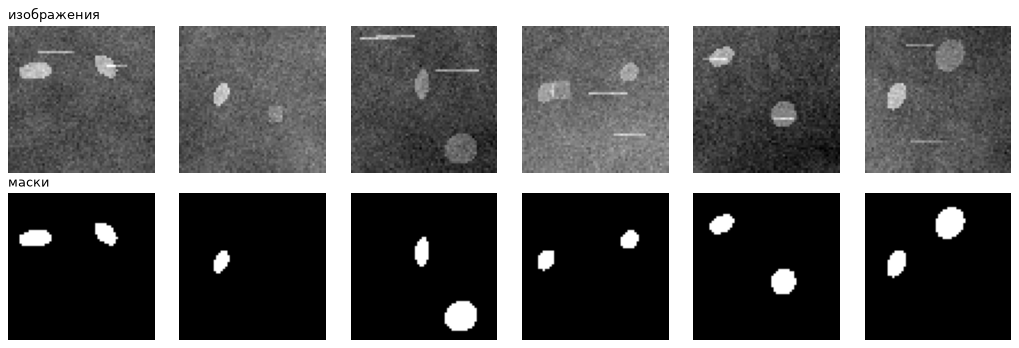

In [4]:
def make_sample(rng, size=SIZE):
    yy, xx = np.mgrid[0:size, 0:size].astype(np.float32)
    img = 0.35 + 0.15 * (xx / size) * rng.uniform(-1, 1) + 0.15 * (yy / size) * rng.uniform(-1, 1)   # неровный фон
    img += cv2.GaussianBlur(rng.normal(0, 0.25, (size, size)).astype(np.float32), (0, 0), 4)       # крупные пятна фона
    mask = np.zeros((size, size), np.float32)
    for _ in range(rng.integers(1, 3)):                                                             # объект: светлые пятна
        cx, cy = rng.uniform(8, size - 8, 2); a, b = rng.uniform(3, 8, 2); th = rng.uniform(0, np.pi)
        u = (xx - cx) * np.cos(th) + (yy - cy) * np.sin(th); v = -(xx - cx) * np.sin(th) + (yy - cy) * np.cos(th)
        blob = (u / a) ** 2 + (v / b) ** 2 <= 1
        mask[blob] = 1; img[blob] += rng.uniform(0.18, 0.45)
    for _ in range(rng.integers(1, 4)):                                                             # отвлекающие детали
        x0, y0 = rng.integers(2, size - 12, 2)
        if rng.random() < 0.5: img[y0:y0 + rng.integers(4, 9), x0:x0 + rng.integers(4, 9)] += rng.uniform(0.08, 0.2)
        else: img[y0, x0:x0 + rng.integers(8, 20)] += rng.uniform(0.2, 0.4)
    img += rng.normal(0, 0.05, (size, size))
    return np.clip(img, 0, 1).astype(np.float32), mask

def make_set(n, seed):
    rng = np.random.default_rng(seed)
    xs, ys = zip(*[make_sample(rng) for _ in range(n)])
    return torch.tensor(np.stack(xs))[:, None], torch.tensor(np.stack(ys))[:, None]

Xtr, Ytr = make_set(N_TRAIN, SEED); Xva, Yva = make_set(N_VAL, SEED + 1); Xte, Yte = make_set(N_TEST, SEED + 2)
assert Xtr.shape == Ytr.shape and Xva.shape == Yva.shape
print("train:", tuple(Xtr.shape), " val:", tuple(Xva.shape), " test:", tuple(Xte.shape))
fg = Ytr.mean().item()
print(f"доля foreground: train {fg:.4f}, val {Yva.mean().item():.4f}, test {Yte.mean().item():.4f}")
print(f"accuracy модели «всё — фон» на val: {1 - Yva.mean().item():.4f}")

fig, ax = plt.subplots(2, 6, figsize=(13, 4.4))
for j in range(6):
    ax[0, j].imshow(Xtr[j, 0], vmin=0, vmax=1); ax[1, j].imshow(Ytr[j, 0], vmin=0, vmax=1)
    ax[0, j].axis("off"); ax[1, j].axis("off")
ax[0, 0].set_title("изображения", loc="left"); ax[1, 0].set_title("маски", loc="left")
plt.tight_layout(); plt.show()

### Шаг 2. Модель и logits

Маленькая U-Net: два уровня сжатия, «дно» и два уровня расширения. На выходе — **один logit на пиксель**, без sigmoid: sigmoid будет внутри loss.

In [5]:
def block(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1), nn.ReLU(), nn.Conv2d(cout, cout, 3, padding=1), nn.ReLU())

class TinyUNet(nn.Module):
    def __init__(self, c=8):
        super().__init__()
        self.e1, self.e2, self.bott = block(1, c), block(c, 2 * c), block(2 * c, 4 * c)
        self.pool = nn.MaxPool2d(2); self.up = nn.Upsample(scale_factor=2, mode="nearest")
        self.d2, self.d1 = block(4 * c + 2 * c, 2 * c), block(2 * c + c, c)
        self.out = nn.Conv2d(c, 1, 1)
    def forward(self, x):
        e1 = self.e1(x); e2 = self.e2(self.pool(e1)); b = self.bott(self.pool(e2))
        d2 = self.d2(torch.cat([self.up(b), e2], 1))         # skip-соединение: детали из e2
        d1 = self.d1(torch.cat([self.up(d2), e1], 1))        # skip-соединение: детали из e1
        return self.out(d1)

torch.manual_seed(SEED)
probe = TinyUNet()
z = probe(Xtr[:4])
print("вход:", tuple(Xtr[:4].shape), "→ logits:", tuple(z.shape), "| параметров:", sum(p.numel() for p in probe.parameters()))
print(f"logits необученной сети: от {z.min().item():.3f} до {z.max().item():.3f} — это не вероятности")

вход: (4, 1, 64, 64) → logits: (4, 1, 64, 64) | параметров: 29617
logits необученной сети: от -0.347 до -0.324 — это не вероятности


### Шаги 3–5. Собственные BCE with logits и soft Dice; проверка на векторах из вопросов

**Stable BCE with logits.** Подставим $p=\sigma(z)$ в формулу BCE и упростим:

$$L=\max(z,0)-z\,y+\ln\big(1+e^{-|z|}\big)$$

В этой записи экспонента берётся только от неположительного числа ($-|z|\le0$), поэтому переполнения быть не может, а логарифм — от числа между 1 и 2. Вывод: $-\ln\sigma(z)=\ln(1+e^{-z})$ и $-\ln(1-\sigma(z))=z+\ln(1+e^{-z})$, откуда $L=(1-y)z+\ln(1+e^{-z})$; для $z<0$ выносим $e^{-z}$ из-под логарифма, чтобы показатель стал отрицательным.

**Soft Dice** считается на вероятностях `sigmoid(z)`, без порога, отдельно для каждой картинки (суммирование по каналу, высоте и ширине — измерения 1, 2, 3), затем усредняется по batch.

In [6]:
def bce_with_logits(z, y):
    """Stable BCE: max(z,0) − z·y + log(1 + exp(−|z|)), среднее по всем пикселям."""
    return (z.clamp(min=0) - z * y + torch.log1p(torch.exp(-z.abs()))).mean()

def soft_dice(prob, target, eps=1e-7):
    inter = (prob * target).sum(dim=(1, 2, 3))
    den = prob.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    return ((2 * inter + eps) / (den + eps)).mean()

def bce_dice_loss(z, y):
    return bce_with_logits(z, y) + (1 - soft_dice(torch.sigmoid(z), y))

def as4d(v): return torch.tensor(v, dtype=torch.float64).reshape(1, 1, 1, -1)
logit = lambda p: np.log(p / (1 - p))

# вопрос 1: те же вероятности, поданные как logits
print("BCE вопроса 1 (своя, через logits):", round(bce_with_logits(as4d(logit(p)), as4d(y)).item(), 5), " ожидается 0.23617")
print("soft Dice вопроса 2 (своя)        :", round(soft_dice(as4d(p2), as4d(y2)).item(), 5), " ожидается 0.73684")

zb, yb = probe(Xtr[:8]).double(), Ytr[:8].double()
print("на batch: своя BCE =", bce_with_logits(zb, yb).item(), " nn.BCEWithLogitsLoss =", nn.BCEWithLogitsLoss()(zb, yb).item())
print("наивная запись −[y·log σ(z) + (1−y)·log(1−σ(z))] на том же batch:", nn.functional.binary_cross_entropy(torch.sigmoid(zb), yb).item())

BCE вопроса 1 (своя, через logits): 0.23617  ожидается 0.23617
soft Dice вопроса 2 (своя)        : 0.73684  ожидается 0.73684
на batch: своя BCE = 0.5495921689512713  nn.BCEWithLogitsLoss = 0.5495921689512713
наивная запись −[y·log σ(z) + (1−y)·log(1−σ(z))] на том же batch: 0.5495921689512713


### Проверка градиентов конечными разностями (шаг 11)

Для одного logit: сдвигаем его на $\pm h$ и считаем $\dfrac{L(z+h)-L(z-h)}{2h}$. Сравниваем с тем, что даёт autograd, а для BCE — ещё и с аналитической формулой $(p-y)/N$ (деление на $N$ — потому что loss усреднён по $N$ пикселям).

In [7]:
torch.manual_seed(1)
zc = torch.randn(2, 1, 6, 6, dtype=torch.float64, requires_grad=True)
yc = (torch.rand(2, 1, 6, 6) > 0.7).double()
idx = (0, 0, 2, 3); h = 1e-5

def finite_diff(loss_fn):
    zp, zm = zc.detach().clone(), zc.detach().clone()
    zp[idx] += h; zm[idx] -= h
    return ((loss_fn(zp, yc) - loss_fn(zm, yc)) / (2 * h)).item()

for name, fn in [("BCE", bce_with_logits), ("1 − soft Dice", lambda z, y: 1 - soft_dice(torch.sigmoid(z), y)), ("BCE + Dice", bce_dice_loss)]:
    zc.grad = None; fn(zc, yc).backward()
    print(f"{name:14}: autograd = {zc.grad[idx].item():+.8f}, конечные разности = {finite_diff(fn):+.8f}")
print(f"{'BCE аналит.':14}: (p − y)/N    = {((torch.sigmoid(zc.detach()) - yc) / zc.numel())[idx].item():+.8f}")

# почему в loss нельзя использовать hard Dice
zc.grad = None
hard = (torch.sigmoid(zc) > 0.5).double()
print("\nhard mask зависит от logits дифференцируемо?", hard.requires_grad, "— порог обрывает граф вычислений, градиента нет")

BCE           : autograd = +0.01030511, конечные разности = +0.01030511
1 − soft Dice : autograd = +0.00103120, конечные разности = +0.00103120
BCE + Dice    : autograd = +0.01133632, конечные разности = +0.01133632
BCE аналит.   : (p − y)/N    = +0.01030511

hard mask зависит от logits дифференцируемо? False — порог обрывает граф вычислений, градиента нет


### Шаги 6–7. Обучение: BCE и BCE + Dice

Две модели с одинаковой архитектурой и **одинаковыми начальными весами** (один seed), одинаковым порядком batch'ей. Отличается только функция потерь. После каждой эпохи на валидации считаются BCE, soft Dice и hard Dice при пороге 0.5.

BCE       : 20.5 с; последняя эпоха: val BCE 0.0145, soft Dice 0.8588, hard Dice@0.5 0.9129


BCE+Dice  : 21.7 с; последняя эпоха: val BCE 0.0201, soft Dice 0.8987, hard Dice@0.5 0.9169


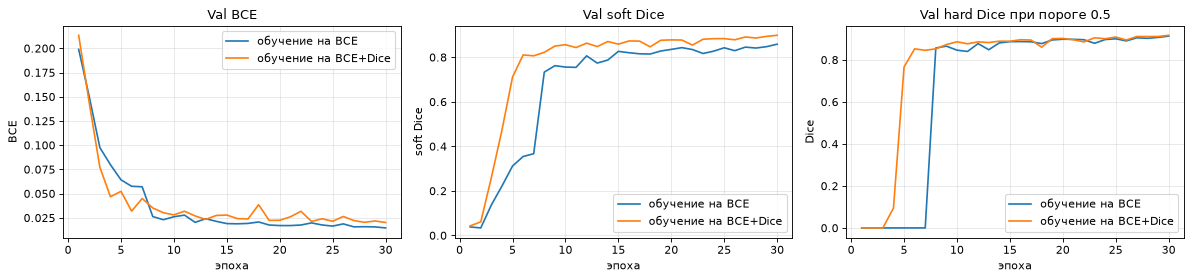

эпоха  1: hard Dice@0.5 — BCE 0.000, BCE+Dice 0.000
эпоха  3: hard Dice@0.5 — BCE 0.000, BCE+Dice 0.000
эпоха  5: hard Dice@0.5 — BCE 0.000, BCE+Dice 0.766
эпоха 10: hard Dice@0.5 — BCE 0.846, BCE+Dice 0.886


In [8]:
def hard_metrics(prob, target, thr):
    """IoU и Dice по всем пикселям набора (TP/FP/FN суммируются по всем картинкам)."""
    pred = prob > thr; t = target > 0.5
    tp = (pred & t).sum().item(); fp = (pred & ~t).sum().item(); fn = (~pred & t).sum().item()
    return tp / (tp + fp + fn + 1e-12), 2 * tp / (2 * tp + fp + fn + 1e-12)

@torch.no_grad()
def predict(model, X):
    model.eval()
    return torch.sigmoid(torch.cat([model(X[i:i + 64].to(device)) for i in range(0, len(X), 64)]).cpu())

def train(loss_fn, name):
    torch.manual_seed(SEED)
    model = TinyUNet().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    g = torch.Generator().manual_seed(SEED)
    hist = []
    t0 = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        perm = torch.randperm(len(Xtr), generator=g)
        for i in range(0, len(perm), BATCH):
            b = perm[i:i + BATCH]
            loss = loss_fn(model(Xtr[b].to(device)), Ytr[b].to(device))
            opt.zero_grad(); loss.backward(); opt.step()
        pv = predict(model, Xva)
        zv = torch.logit(pv.clamp(1e-7, 1 - 1e-7))
        hist.append((epoch, bce_with_logits(zv, Yva).item(), soft_dice(pv, Yva).item(), hard_metrics(pv, Yva, 0.5)[1]))
    print(f"{name:10}: {time.perf_counter() - t0:.1f} с; последняя эпоха: val BCE {hist[-1][1]:.4f}, soft Dice {hist[-1][2]:.4f}, hard Dice@0.5 {hist[-1][3]:.4f}")
    return model, np.array(hist)

model_bce, hist_bce = train(bce_with_logits, "BCE")
model_mix, hist_mix = train(bce_dice_loss, "BCE+Dice")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for k, title, yl in [(1, "Val BCE", "BCE"), (2, "Val soft Dice", "soft Dice"), (3, "Val hard Dice при пороге 0.5", "Dice")]:
    ax[k - 1].plot(hist_bce[:, 0], hist_bce[:, k], label="обучение на BCE"); ax[k - 1].plot(hist_mix[:, 0], hist_mix[:, k], label="обучение на BCE+Dice")
    ax[k - 1].set(title=title, xlabel="эпоха", ylabel=yl); ax[k - 1].legend(); ax[k - 1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
for e in (1, 3, 5, 10):
    print(f"эпоха {e:2d}: hard Dice@0.5 — BCE {hist_bce[e - 1, 3]:.3f}, BCE+Dice {hist_mix[e - 1, 3]:.3f}")

### Шаги 8–9. Пороги 0.3–0.7 на валидации и выбор порога

Порог выбирается по **валидации** — по лучшему Dice. Тест используется один раз, в самом конце, с уже выбранным порогом: если подбирать порог по тесту, итоговая цифра будет завышена.

In [9]:
results = {}
for name, model in [("BCE", model_bce), ("BCE+Dice", model_mix)]:
    pv = predict(model, Xva)
    print(f"{name}: порог → (IoU, Dice) на val")
    rows = [(t,) + hard_metrics(pv, Yva, t) for t in THRESHOLDS]
    for t, iou, dice in rows: print(f"    {t:.1f} → IoU {iou:.4f}, Dice {dice:.4f}")
    best = max(rows, key=lambda r: r[2])
    results[name] = dict(thr=best[0], val_iou=best[1], val_dice=best[2], spread=max(r[2] for r in rows) - min(r[2] for r in rows))

print(f"\n{'Loss':10}{'Best val IoU':>14}{'Best val Dice':>15}{'Best threshold':>16}{'Test IoU':>10}{'Test Dice':>11}{'разброс Dice по порогам':>26}")
for name, model in [("BCE", model_bce), ("BCE+Dice", model_mix)]:
    r = results[name]
    r["test_iou"], r["test_dice"] = hard_metrics(predict(model, Xte), Yte, r["thr"])
    print(f"{name:10}{r['val_iou']:14.4f}{r['val_dice']:15.4f}{r['thr']:16.1f}{r['test_iou']:10.4f}{r['test_dice']:11.4f}{r['spread']:26.4f}")

# насколько «уверенны» вероятности: доля пикселей с p между 0.1 и 0.9
for name, model in [("BCE", model_bce), ("BCE+Dice", model_mix)]:
    pv = predict(model, Xva)
    print(f"{name:10}: доля «неуверенных» пикселей (0.1 < p < 0.9) = {((pv > 0.1) & (pv < 0.9)).float().mean().item():.4f}; средняя p на объекте = {pv[Yva > 0.5].mean().item():.3f}")

BCE: порог → (IoU, Dice) на val
    0.3 → IoU 0.8200, Dice 0.9011
    0.4 → IoU 0.8338, Dice 0.9094
    0.5 → IoU 0.8398, Dice 0.9129
    0.6 → IoU 0.8375, Dice 0.9116
    0.7 → IoU 0.8257, Dice 0.9045
BCE+Dice: порог → (IoU, Dice) на val
    0.3 → IoU 0.8390, Dice 0.9125
    0.4 → IoU 0.8424, Dice 0.9145
    0.5 → IoU 0.8465, Dice 0.9169
    0.6 → IoU 0.8486, Dice 0.9181
    0.7 → IoU 0.8487, Dice 0.9182

Loss        Best val IoU  Best val Dice  Best threshold  Test IoU  Test Dice   разброс Dice по порогам


BCE               0.8398         0.9129             0.5    0.8510     0.9195                    0.0119


BCE+Dice          0.8487         0.9182             0.7    0.8667     0.9286                    0.0057
BCE       : доля «неуверенных» пикселей (0.1 < p < 0.9) = 0.0170; средняя p на объекте = 0.880
BCE+Dice  : доля «неуверенных» пикселей (0.1 < p < 0.9) = 0.0066; средняя p на объекте = 0.926


### Шаг 10. Original, GT, prediction, карта ошибок

Три тестовых примера: лучший, средний и худший по Dice для модели BCE+Dice. На карте ошибок: зелёный — TP, красный — FP, синий — FN.

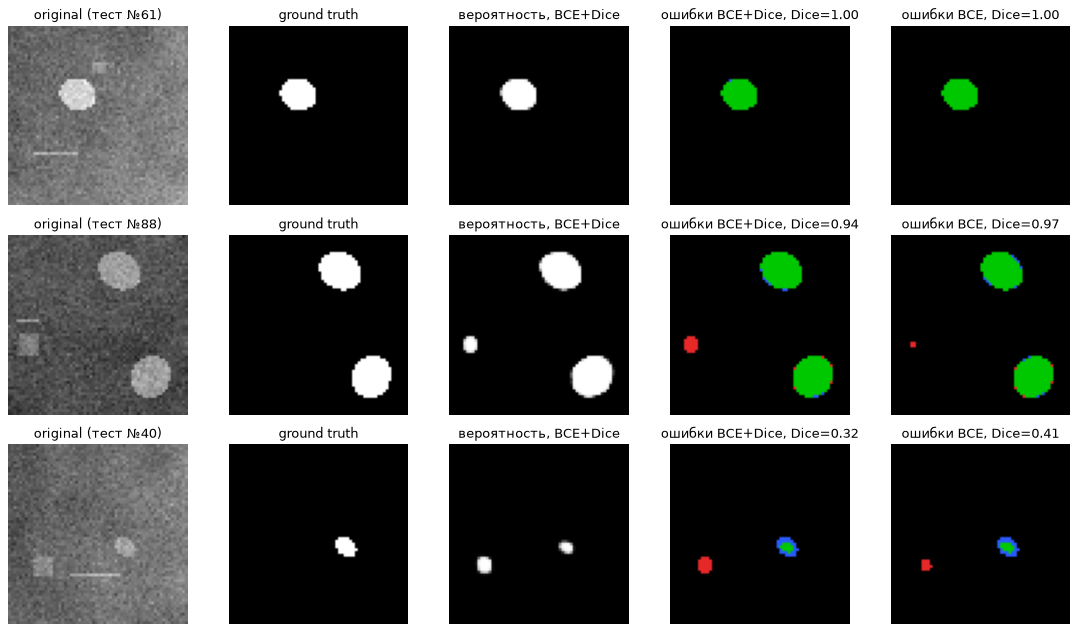

Dice по картинкам теста (BCE+Dice): медиана 0.941, худшие пять: [0.325 0.671 0.702 0.704 0.743]


In [10]:
def per_image_dice(prob, target, thr):
    pred = (prob > thr).float()
    inter = (pred * target).sum(dim=(1, 2, 3)); den = pred.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    return ((2 * inter + 1e-7) / (den + 1e-7)).numpy()

def error_map(pred, gt):
    out = np.zeros(gt.shape + (3,), np.uint8)
    out[pred & gt] = (0, 200, 0); out[pred & ~gt] = (230, 40, 40); out[~pred & gt] = (40, 90, 255)
    return out

thr_mix = results["BCE+Dice"]["thr"]
p_mix, p_bce = predict(model_mix, Xte), predict(model_bce, Xte)
dice_img = per_image_dice(p_mix, Yte, thr_mix)
order = np.argsort(dice_img)
picks = [order[-1], order[len(order) // 2], order[0]]
fig, ax = plt.subplots(3, 5, figsize=(14, 8))
for row, i in enumerate(picks):
    gt = Yte[i, 0].numpy() > 0.5
    ax[row, 0].imshow(Xte[i, 0], vmin=0, vmax=1); ax[row, 0].set_title(f"original (тест №{i})")
    ax[row, 1].imshow(gt); ax[row, 1].set_title("ground truth")
    ax[row, 2].imshow(p_mix[i, 0], vmin=0, vmax=1); ax[row, 2].set_title("вероятность, BCE+Dice")
    ax[row, 3].imshow(error_map(p_mix[i, 0].numpy() > thr_mix, gt)); ax[row, 3].set_title(f"ошибки BCE+Dice, Dice={dice_img[i]:.2f}")
    ax[row, 4].imshow(error_map(p_bce[i, 0].numpy() > results["BCE"]["thr"], gt)); ax[row, 4].set_title(f"ошибки BCE, Dice={per_image_dice(p_bce, Yte, results['BCE']['thr'])[i]:.2f}")
    for a_ in ax[row]: a_.axis("off")
plt.tight_layout(); plt.show()
print(f"Dice по картинкам теста (BCE+Dice): медиана {np.median(dice_img):.3f}, худшие пять: {np.round(np.sort(dice_img)[:5], 3)}")

## 5. Неудачные случаи

### Pixel accuracy при редком объекте

In [11]:
empty = torch.zeros_like(Yte)
acc_empty = (empty == Yte).float().mean().item()
print(f"маска «всё — фон»: pixel accuracy = {acc_empty:.4f}, IoU = {hard_metrics(empty, Yte, 0.5)[0]:.4f}, Dice = {hard_metrics(empty, Yte, 0.5)[1]:.4f}")
for name, model in [("BCE", model_bce), ("BCE+Dice", model_mix)]:
    pt = predict(model, Xte); thr = results[name]["thr"]
    acc = ((pt > thr).float() == Yte).float().mean().item()
    print(f"{name:10}: pixel accuracy = {acc:.4f}, Dice = {hard_metrics(pt, Yte, thr)[1]:.4f}")
print(f"BCE пустого ответа с logit = −4 во всех пикселях: {bce_with_logits(torch.full_like(Yte, -4.0), Yte).item():.4f}")
print(f"BCE необученной сети: {bce_with_logits(probe(Xte), Yte).item():.4f}")

маска «всё — фон»: pixel accuracy = 0.9631, IoU = 0.0000, Dice = 0.0000
BCE       : pixel accuracy = 0.9941, Dice = 0.9195
BCE+Dice  : pixel accuracy = 0.9948, Dice = 0.9286
BCE пустого ответа с logit = −4 во всех пикселях: 0.1659


BCE необученной сети: 0.5503


Маска, в которой нет ни одного пикселя объекта, получает pixel accuracy 0.963 — всего на три процентных пункта меньше, чем у обученных моделей (0.994 и 0.995). По accuracy эти результаты почти неразличимы; по Dice — 0 против 0.92–0.93. И BCE у «пустого» ответа (0.17) втрое ниже, чем у необученной сети (0.55): первое, чему учится сеть при редком объекте, — отвечать «везде фон». Это видно и в динамике обучения: первые эпохи hard Dice у обеих моделей равен нулю.

### Наивная BCE: sigmoid, затем log

In [12]:
zs = torch.tensor([-800.0, -40.0, 0.5, 40.0, 800.0], dtype=torch.float64)
ys = torch.tensor([1.0, 1.0, 1.0, 0.0, 0.0], dtype=torch.float64)        # сеть уверенно ошибается на краях
ps = torch.sigmoid(zs)
naive = -(ys * torch.log(ps) + (1 - ys) * torch.log(1 - ps))
stable = zs.clamp(min=0) - zs * ys + torch.log1p(torch.exp(-zs.abs()))
print("logits      :", zs.tolist())
print("sigmoid     :", ps.tolist())
print("наивная BCE :", naive.tolist())
print("stable BCE  :", stable.tolist())

zg = zs.clone().requires_grad_(True)
pg = torch.sigmoid(zg)
(-(ys * torch.log(pg) + (1 - ys) * torch.log(1 - pg))).sum().backward()
print("градиент наивной BCE:", zg.grad.tolist(), "← nan там, где нужен самый сильный сигнал")
zg2 = zs.clone().requires_grad_(True)
(zg2.clamp(min=0) - zg2 * ys + torch.log1p(torch.exp(-zg2.abs()))).sum().backward()
print("градиент stable BCE :", zg2.grad.tolist(), "= p − y")

logits      : [-800.0, -40.0, 0.5, 40.0, 800.0]
sigmoid     : [0.0, 4.248354255291589e-18, 0.6224593312018546, 1.0, 1.0]
наивная BCE : [inf, 40.0, 0.47407698418010663, inf, inf]
stable BCE  : [800.0, 40.0, 0.4740769841801067, 40.0, 800.0]
градиент наивной BCE: [nan, -1.0, -0.37754066879814546, nan, nan] ← nan там, где нужен самый сильный сигнал
градиент stable BCE : [-1.0, -1.0, -0.3775406687981455, 1.0, 1.0] = p − y


При logit = +40 сигмоида в `float64` округляется ровно до 1, $1-p=0$, и $\ln0=-\infty$: loss бесконечен, градиент — `nan`. При ±800 то же самое с обеих сторон. Причём ломается всё именно там, где сеть уверенно ошибается и градиент нужнее всего. Стабильная формула в тех же точках даёт конечный loss (равный $|z|$) и градиент ±1, а в обычной точке $z=0.5$ обе формулы совпадают.

### Худший пример модели

Нижняя строка картинки шага 10 — тестовый пример №40 с наименьшим Dice (0.32 у BCE+Dice, 0.41 у BCE). В нём две ошибки сразу:

- **FN:** объект маленький и слабоконтрастный — он лишь немного светлее фона. Обе модели нашли только его центр, края пропущены.
- **FP:** тусклый квадрат слева — отвлекающая деталь — принят за объект. По яркости он почти такой же, как настоящее пятно.

Та же ошибка FP есть в средней строке (пример №88): квадрат слева помечен как объект, причём у модели BCE+Dice пятно крупнее. Dice-слагаемое поощряет «решительные» ответы: это повышает recall на настоящих объектах, но и ложное срабатывание получается уверенным и крупным. Метрики по всему набору такие случаи усредняют: медианный Dice по картинкам теста 0.94, а у пяти худших — от 0.32 до 0.74.

## 6. Вывод

Данные синтетические; цифры — из таблиц шагов 6–9.

- **Ручные расчёты:** средняя BCE = 0.2362; soft Dice = 0.7368; градиент BCE по logit равен $p-y=-0.2$. Все три подтверждены собственными функциями и PyTorch; градиенты BCE, Dice и их суммы совпали с конечными разностями до восьмого знака.
- **Собственные loss-функции.** Stable BCE совпадает с `nn.BCEWithLogitsLoss` до последнего знака; наивная запись через sigmoid и log на обычных значениях даёт то же, но на больших logits — `inf` и `nan` (раздел 5).
- **BCE против BCE+Dice:**

| Loss | Best val IoU | Best val Dice | Best threshold | Test IoU | Test Dice | Комментарий |
|---|---|---|---|---|---|---|
| BCE | 0.840 | 0.913 | 0.5 | 0.851 | 0.920 | позже начинает находить объект; чувствительнее к порогу |
| BCE+Dice | 0.849 | 0.918 | 0.7 | 0.867 | 0.929 | быстрее выходит из «всё — фон»; вероятности решительнее |

  - *Итоговое качество* почти одинаково: разница в Dice — 0.005 на валидации и 0.009 на тесте. Для одного запуска с одним seed это не позволяет утверждать, что BCE+Dice лучше; нужны повторы с разными seed.
  - *Динамика* различается заметнее. Первые три эпохи обе модели выдают пустую маску (hard Dice = 0). На пятой эпохе модель BCE+Dice уже даёт Dice 0.77, модель BCE — всё ещё 0; на десятой — 0.89 против 0.85. Dice-слагаемое не даёт «отсидеться» в ответе «везде фон»: у пустой маски $1-\mathrm{Dice}=1$, максимальный штраф.
  - *Чувствительность к порогу.* При изменении порога от 0.3 до 0.7 Dice модели BCE меняется на 0.012, модели BCE+Dice — на 0.006. Причина — вероятности: у BCE+Dice только 0.7 % пикселей имеют «неуверенную» вероятность между 0.1 и 0.9, у BCE — 1.7 %; средняя вероятность на объекте 0.93 против 0.88.
  - *BCE на валидации* у модели BCE+Dice хуже (0.020 против 0.015): она оптимизировала другой критерий. Какая модель «лучше», зависит от того, какой метрикой это измерять.
- **Почему soft Dice без порога.** Порог — ступенчатая функция, её производная почти всюду ноль, и граф вычислений на ней обрывается (проверено: `requires_grad=False`). Soft Dice использует вероятности и остаётся дифференцируемым; hard Dice с порогом — метрика для оценки, а не loss.
- **Почему BCE и Dice складывают.** BCE даёт каждому пикселю ровный градиент $p-y$, но при дисбалансе тонет в фоне. Dice нацелен на перекрытие и к фону нечувствителен, но его градиент зависит от суммарных площадей и на первых шагах, когда предсказание почти пусто, мал и нестабилен. Сумма сочетает устойчивость первого с целевой направленностью второго.
- **Ошибки.** FN — слабоконтрастные пятна и края объекта; FP — отвлекающие квадраты, похожие по яркости. Pixel accuracy эти различия не показывает: она 0.963 даже у пустой маски.
- **Порог выбран по валидации**, тест использован один раз. Тестовые Dice (0.920 и 0.929) оказались чуть выше валидационных — это разброс между наборами по 100 картинок, а не эффект выбора порога.
- **Ограничение:** данные синтетические, один запуск на каждый вариант; на реальных снимках с неточной разметкой границ соотношение между loss-функциями может быть другим.

## 7. Вопросы на защиту

**1. Чем logits отличаются от probabilities и почему BCEWithLogitsLoss предпочтительнее sigmoid+log вручную?**
Logit — неограниченное число на выходе сети; вероятность — результат sigmoid, от 0 до 1. `BCEWithLogitsLoss` принимает logits и считает loss формулой $\max(z,0)-zy+\ln(1+e^{-|z|})$, в которой нет ни переполнения экспоненты, ни логарифма нуля. При раздельном вычислении sigmoid округляется до 0 или 1 уже при $|z|\approx37$ (в `float32` — около 17), после чего $\ln0=-\infty$, а градиент превращается в `nan`.

**2. Почему Dice особенно полезен при дисбалансе foreground/background?**
В формулу Dice не входят TN — правильно угаданный фон. Числитель и знаменатель определяются только объектом и предсказанием, поэтому значение не зависит от того, сколько в кадре фона. BCE — среднее по всем пикселям: при 4 % объекта 96 % слагаемых относятся к фону, и «пустой» ответ уже даёт малый loss. Dice пустого ответа равен нулю.

**3. Собственная Dice-функция; по каким измерениям выполняется суммирование.**
`inter = (prob * target).sum(dim=(1, 2, 3))` и `den = prob.sum(dim=(1,2,3)) + target.sum(dim=(1,2,3))`: тензоры имеют форму `B×C×H×W`, суммирование идёт по каналу, высоте и ширине, то есть **внутри каждой картинки**; измерение 0 (batch) не трогается. Получается по одному значению Dice на картинку, затем `.mean()` усредняет их по batch. Если суммировать по всем четырём измерениям сразу, картинки с крупными объектами перевесят картинки с мелкими.